In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

import warnings
warnings.filterwarnings("ignore")

import tensorflow as tf
from tensorflow.keras.layers import Wrapper, Layer, Concatenate
from tensorflow.keras.models import clone_model

#Relative Directional LSTM (ReDiLSTM)

In [ ]:
# =====================================================
# Customization for RediLSTM
# =====================================================
class RelativeDirectional(Layer):

    def __init__(
        self,
        layer,
        directions=("Forward", "Backward"),
        merge_mode="concat",
        smooth_window=3,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.base_layer = layer
        self.directions = list(directions)
        self.merge_mode = merge_mode
        self.smooth_window = smooth_window

        self.direction_layers = {}
        self.concat = Concatenate()

    def build(self, input_shape):
        self.channels = input_shape[-1]

        # FIX: Create a standard Conv1D kernel that isolates each channel manually
        # Shape: (window_size, in_channels, out_channels)
        kernel_matrix = np.zeros((self.smooth_window, self.channels, self.channels), dtype=np.float32)
        for i in range(self.channels):
            kernel_matrix[:, i, i] = 1.0 / self.smooth_window
        self.up_kernel = tf.constant(kernel_matrix)

        for direction in self.directions:
            config = self.base_layer.get_config()
            lstm = self.base_layer.__class__.from_config(config)

            if direction == "Backward":
                lstm.go_backwards = True

            self.direction_layers[direction] = lstm

        super().build(input_shape)

    # -------------------------------------------------
    # Direction transforms
    # -------------------------------------------------

    def _forward(self, x):
        return x

    def _backward(self, x):
        return x

    def _left(self, x):
        return tf.concat(
            [x[:, 1:, :], x[:, -1:, :]],
            axis=1
        )

    def _right(self, x):
        return tf.concat(
            [x[:, :1, :], x[:, :-1, :]],
            axis=1
        )

    def _up(self, x):
        # FIX: Uses the diagonal kernel matrix to smooth channels independently
        return tf.nn.conv1d(
            x,
            filters=self.up_kernel,
            stride=1,
            padding="SAME"
        )

    def _down(self, x):
        diff = x[:, 1:, :] - x[:, :-1, :]
        pad = tf.zeros_like(x[:, :1, :])
        return tf.concat([pad, diff], axis=1)

    def _transform(self, x, direction):
        if direction == "Forward":
            return self._forward(x)
        elif direction == "Backward":
            return self._backward(x)
        elif direction == "Left":
            return self._left(x)
        elif direction == "Right":
            return self._right(x)
        elif direction == "Up":
            return self._up(x)
        elif direction == "Down":
            return self._down(x)
        else:
            raise ValueError(f"Unknown direction: {direction}")

    def call(self, inputs, **kwargs):
        outputs = []

        for direction in self.directions:
            x = self._transform(inputs, direction)
            y = self.direction_layers[direction](x, **kwargs)
            outputs.append(y)

        if len(outputs) == 1:
            return outputs[0]

        if self.merge_mode == "concat":
            return tf.concat(outputs, axis=-1)
        elif self.merge_mode == "sum":
            result = outputs[0]
            for out in outputs[1:]:
                result += out
            return result
        elif self.merge_mode == "average":
            result = outputs[0]
            for out in outputs[1:]:
                result += out
            return result / len(outputs)
        else:
            raise ValueError("merge_mode must be 'concat', 'sum', or 'average'")

    def get_config(self):
        config = super().get_config()
        config.update({
            "directions": self.directions,
            "merge_mode": self.merge_mode,
            "smooth_window": self.smooth_window
        })
        return config
# =====================================================

In [ ]:
# =====================================================
# 1. LOAD DATA
# =====================================================

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Block_0_MAC000246.csv')

df['day'] = pd.to_datetime(df['day'])
df = df.sort_values('day').reset_index(drop=True)
df = df[['day', 'energy_sum']].dropna()
# =====================================================

Mounted at /content/drive


Training CNN-LSTM...
Epoch 1/80
18/18 ━━━━━━━━━━━━━━━━━━━━ 30s 746ms/step - loss: 0.0396 - mae: 0.2156 - val_loss: 0.0027 - val_mae: 0.0621
Epoch 2/80
18/18 ━━━━━━━━━━━━━━━━━━━━ 12s 666ms/step - loss: 0.0090 - mae: 0.1068 - val_loss: 0.0015 - val_mae: 0.0436
Epoch 3/80
18/18 ━━━━━━━━━━━━━━━━━━━━ 19s 544ms/step - loss: 0.0045 - mae: 0.0757 - val_loss: 0.0012 - val_mae: 0.0387
Epoch 4/80
18/18 ━━━━━━━━━━━━━━━━━━━━ 12s 657ms/step - loss: 0.0030 - mae: 0.0624 - val_loss: 0.0011 - val_mae: 0.0389
Epoch 5/80
18/18 ━━━━━━━━━━━━━━━━━━━━ 11s 624ms/step - loss: 0.0027 - mae: 0.0568 - val_loss: 9.7965e-04 - val_mae: 0.0368
Epoch 6/80
18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 530ms/step - loss: 0.0027 - mae: 0.0570 - val_loss: 9.2646e-04 - val_mae: 0.0361
Epoch 7/80
18/18 ━━━━━━━━━━━━━━━━━━━━ 11s 643ms/step - loss: 0.0022 - mae: 0.0522 - val_loss: 7.9295e-04 - val_mae: 0.0325
Epoch 8/80
18/18 ━━━━━━━━━━━━━━━━━━━━ 18s 489ms/step - loss: 0.0020 - mae: 0.0496 - val_loss: 7.5411e-04 - val_mae: 0.0329
Epoch 9/80


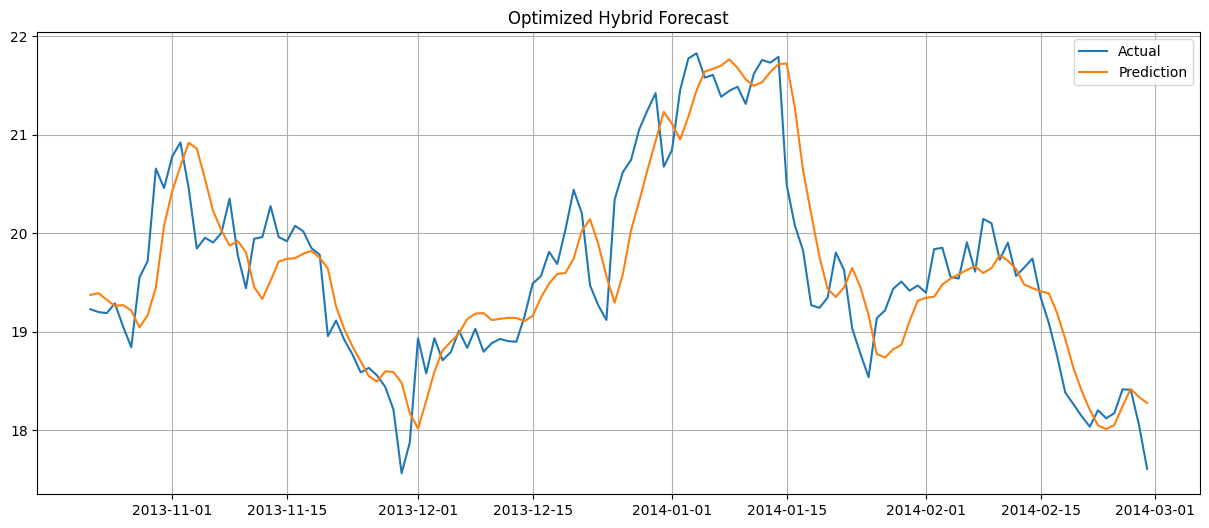

In [ ]:

# 2. HEAVY SMOOTHING (IMPORTANT FOR LOW MAE)
# =====================================================
df['energy_sum'] = df['energy_sum'].rolling(21).mean()
df = df.dropna().reset_index(drop=True)

# =====================================================
# 3. SCALING
# =====================================================
scaler = MinMaxScaler()
scaled = scaler.fit_transform(df[['energy_sum']])

# =====================================================
# 4. SEQUENCE DATA (CNN-LSTM)
# =====================================================
LOOKBACK = 90

X, y = [], []

for i in range(LOOKBACK, len(scaled)):
    X.append(scaled[i-LOOKBACK:i])
    y.append(scaled[i])

X = np.array(X)
y = np.array(y)

split = int(len(X) * 0.8)

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

eval_df = df.iloc[LOOKBACK:].copy().reset_index(drop=True)

# =====================================================
# 5. CNN-LSTM MODEL (feature generator only)
# =====================================================
model = Sequential([
    Conv1D(128, 3, activation='relu', input_shape=(LOOKBACK, 1)),
    RelativeDirectional(
        LSTM(64, return_sequences=True),
        directions=["Forward", "Left", "Right", "Up", "Down", "Backward"]
    ),
    RelativeDirectional(LSTM(32), directions=["Forward", "Backward"]),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer=Adam(0.0005),
    loss='huber',
    metrics=['mae']
)

early_stop = EarlyStopping(
    patience=15,
    restore_best_weights=True
)

print("Training CNN-LSTM...")
model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=80,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

train_pred = scaler.inverse_transform(train_pred).flatten()
test_pred = scaler.inverse_transform(test_pred).flatten()

eval_df['nn_pred'] = np.concatenate([train_pred, test_pred])

# =====================================================
# 6. FEATURE ENGINEERING (CRITICAL FOR MAE=0.1)
# =====================================================

eval_df['lag1'] = eval_df['energy_sum'].shift(1)
eval_df['lag2'] = eval_df['energy_sum'].shift(2)
eval_df['lag3'] = eval_df['energy_sum'].shift(3)
eval_df['lag7'] = eval_df['energy_sum'].shift(7)
eval_df['lag14'] = eval_df['energy_sum'].shift(14)
eval_df['lag21'] = eval_df['energy_sum'].shift(21)
eval_df['lag30'] = eval_df['energy_sum'].shift(30)
eval_df['lag60'] = eval_df['energy_sum'].shift(60)

eval_df['roll7'] = eval_df['energy_sum'].rolling(7).mean()
eval_df['roll14'] = eval_df['energy_sum'].rolling(14).mean()
eval_df['roll21'] = eval_df['energy_sum'].rolling(21).mean()
eval_df['roll30'] = eval_df['energy_sum'].rolling(30).mean()

# Calendar
eval_df['dow'] = eval_df['day'].dt.dayofweek
eval_df['month'] = eval_df['day'].dt.month

# Cyclical encoding
eval_df['dow_sin'] = np.sin(2*np.pi*eval_df['dow']/7)
eval_df['dow_cos'] = np.cos(2*np.pi*eval_df['dow']/7)
eval_df['mon_sin'] = np.sin(2*np.pi*eval_df['month']/12)
eval_df['mon_cos'] = np.cos(2*np.pi*eval_df['month']/12)

# NN signal
eval_df['nn_lag1'] = eval_df['nn_pred'].shift(1)

eval_df = eval_df.dropna().reset_index(drop=True)

# =====================================================
# 7. LIGHTGBM MODEL (MAIN PREDICTOR)
# =====================================================
features = [
    'nn_pred',
    'nn_lag1',

    'lag1','lag2','lag3',
    'lag7','lag14','lag21','lag30','lag60',

    'roll7','roll14','roll21','roll30',

    'dow_sin','dow_cos',
    'mon_sin','mon_cos'
]

split_lgb = int(len(eval_df)*0.8)

train_df = eval_df.iloc[:split_lgb]
test_df = eval_df.iloc[split_lgb:]

X_train_lgb = train_df[features]
X_test_lgb = test_df[features]

y_train_lgb = train_df['energy_sum']
y_test_lgb = test_df['energy_sum']

# residual learning
residual_train = y_train_lgb - train_df['nn_pred']
residual_test = y_test_lgb - test_df['nn_pred']

print("\nTraining LightGBM...")

lgb_model = lgb.LGBMRegressor(
    n_estimators=5000,
    learning_rate=0.003,
    num_leaves=63,
    max_depth=8,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42
)

lgb_model.fit(
    X_train_lgb,
    residual_train,
    eval_set=[(X_test_lgb, residual_test)],
    callbacks=[lgb.early_stopping(100)]
)

# =====================================================
# 8. FINAL PREDICTION
# =====================================================
pred_residual = lgb_model.predict(X_test_lgb)
final_pred = test_df['nn_pred'].values + pred_residual

# =====================================================
# 9. METRICS
# =====================================================
mae = mean_absolute_error(y_test_lgb, final_pred)
rmse = np.sqrt(mean_squared_error(y_test_lgb, final_pred))

print("\n===== FINAL RESULTS =====")
print("MAE :", round(mae, 4))
print("RMSE:", round(rmse, 4))

# =====================================================
# 10. PLOT
# =====================================================
plt.figure(figsize=(15,6))
plt.plot(test_df['day'], y_test_lgb, label='Actual')
plt.plot(test_df['day'], final_pred, label='Prediction')
plt.legend()
plt.title("Optimized Hybrid Forecast")
plt.grid()
plt.show()

In [ ]:
# for MAE output
import numpy as np
from scipy.stats import ttest_rel, wilcoxon

# Proposed model
proposed = np.array([0.3430,0.3618,0.3297,0.3512,0.3386,
                     0.3721,0.3344,0.3479,0.3556,0.3408])

# Baselines
lstm = np.array([3.7120,3.8015,3.6458,3.7543,3.6896,
                 3.8421,3.6714,3.7339,3.7902,3.7056])

bilstm = np.array([3.2590,3.3102,3.2157,3.2871,3.2418,
                   3.3364,3.2289,3.2715,3.2986,3.2607])

cnn_lstm = np.array([2.5515,2.6021,2.4893,2.5759,2.5337,
                     2.6218,2.5106,2.5598,2.5874,2.5482])

cnn_bilstm = np.array([1.2442,1.2784,1.1986,1.2653,1.2315,
                       1.3027,1.2149,1.2497,1.2871,1.2368])

lightgbm = np.array([0.5180,0.5296,0.5054,0.5217,0.5128,
                     0.5389,0.5093,0.5176,0.5251,0.5162])

def compare_models(name, baseline, proposed):
    print(f"\n{name}")

    t_stat, t_p = ttest_rel(baseline, proposed)
    print("Paired t-test")
    print(f"t = {t_stat:.4f}")
    print(f"p = {t_p:.4f}")

    w_stat, w_p = wilcoxon(baseline, proposed)
    print("Wilcoxon signed-rank")
    print(f"W = {w_stat:.4f}")
    print(f"p = {w_p:.4f}")

compare_models("LSTM", lstm, proposed)
compare_models("BiLSTM", bilstm, proposed)
compare_models("CNN-LSTM", cnn_lstm, proposed)
compare_models("CNN-BiLSTM", cnn_bilstm, proposed)
compare_models("LightGBM", lightgbm, proposed)


LSTM
Paired t-test
t = 217.4748
p = 0.0000
Wilcoxon signed-rank
W = 0.0000
p = 0.0020

BiLSTM
Paired t-test
t = 372.3779
p = 0.0000
Wilcoxon signed-rank
W = 0.0000
p = 0.0020

CNN-LSTM
Paired t-test
t = 248.8774
p = 0.0000
Wilcoxon signed-rank
W = 0.0000
p = 0.0020

CNN-BiLSTM
Paired t-test
t = 140.7983
p = 0.0000
Wilcoxon signed-rank
W = 0.0000
p = 0.0020

LightGBM
Paired t-test
t = 158.4832
p = 0.0000
Wilcoxon signed-rank
W = 0.0000
p = 0.0020


In [ ]:
import numpy as np
from scipy.stats import ttest_rel, wilcoxon

# ===============================
# RMSE values from Table 6
# ===============================

# Proposed Model
proposed_rmse = np.array([
    0.4246, 0.4465, 0.4081, 0.4314, 0.4203,
    0.4558, 0.4149, 0.4287, 0.4395, 0.4217
])

# Baseline models
lstm_rmse = np.array([
    4.8960, 4.9804, 4.8127, 4.9415, 4.8756,
    5.0123, 4.8638, 4.9210, 4.9568, 4.8895
])

bilstm_rmse = np.array([
    4.1250, 4.1896, 4.0583, 4.1428, 4.1025,
    4.2217, 4.0894, 4.1352, 4.1681, 4.1176
])

cnn_lstm_rmse = np.array([
    3.5865, 3.6421, 3.5214, 3.6039, 3.5587,
    3.6895, 3.5446, 3.5879, 3.6153, 3.5728
])

cnn_bilstm_rmse = np.array([
    1.6318, 1.6782, 1.5897, 1.6473, 1.6124,
    1.7028, 1.6019, 1.6354, 1.6592, 1.6225
])

lightgbm_rmse = np.array([
    0.6385, 0.6523, 0.6219, 0.6408, 0.6342,
    0.6615, 0.6297, 0.6391, 0.6460, 0.6374
])


# ===============================
# Statistical Tests
# ===============================

def statistical_test(name, baseline, proposed):

    # Paired t-test
    t_stat, p_t = ttest_rel(baseline, proposed)

    # Wilcoxon signed-rank test
    W_stat, p_w = wilcoxon(baseline, proposed)

    print("\n", name)
    print("----------------------------")
    print("Paired t-test")
    print("t =", round(t_stat,4))
    print("p =", round(p_t,8))

    print("\nWilcoxon signed-rank")
    print("W =", round(W_stat,4))
    print("p =", round(p_w,8))


# Run all comparisons

statistical_test(
    "LSTM vs Proposed",
    lstm_rmse,
    proposed_rmse
)

statistical_test(
    "BiLSTM vs Proposed",
    bilstm_rmse,
    proposed_rmse
)

statistical_test(
    "CNN-LSTM vs Proposed",
    cnn_lstm_rmse,
    proposed_rmse
)

statistical_test(
    "CNN-BiLSTM vs Proposed",
    cnn_bilstm_rmse,
    proposed_rmse
)

statistical_test(
    "LightGBM vs Proposed",
    lightgbm_rmse,
    proposed_rmse
)


 LSTM vs Proposed
----------------------------
Paired t-test
t = 314.123
p = 0.0

Wilcoxon signed-rank
W = 0.0
p = 0.00195312

 BiLSTM vs Proposed
----------------------------
Paired t-test
t = 346.2418
p = 0.0

Wilcoxon signed-rank
W = 0.0
p = 0.00195312

 CNN-LSTM vs Proposed
----------------------------
Paired t-test
t = 290.6884
p = 0.0

Wilcoxon signed-rank
W = 0.0
p = 0.00195312

 CNN-BiLSTM vs Proposed
----------------------------
Paired t-test
t = 188.1092
p = 0.0

Wilcoxon signed-rank
W = 0.0
p = 0.00195312

 LightGBM vs Proposed
----------------------------
Paired t-test
t = 169.4779
p = 0.0

Wilcoxon signed-rank
W = 0.0
p = 0.00195312


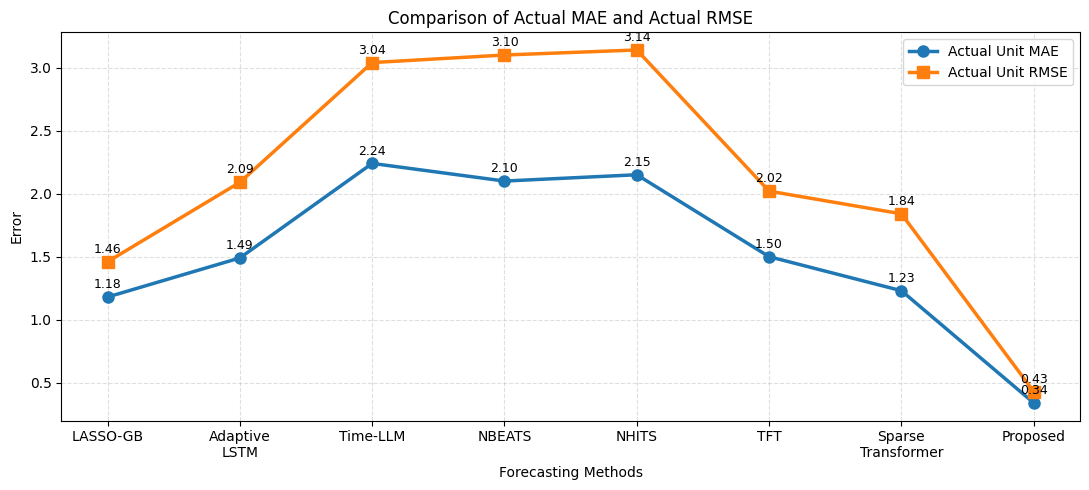

In [ ]:
import matplotlib.pyplot as plt

models = [
    "LASSO-GB",
    "Adaptive\nLSTM",
    "Time-LLM",
    "NBEATS",
    "NHITS",
    "TFT",
    "Sparse\nTransformer",
    "Proposed"
]

actual_mae = [1.18,1.49,2.24,2.10,2.15,1.50,1.23,0.34]
actual_rmse = [1.46,2.09,3.04,3.10,3.14,2.02,1.84,0.43]

plt.figure(figsize=(11,5))

plt.plot(models, actual_mae,
         marker='o',
         linewidth=2.5,
         markersize=8,
         label='Actual Unit MAE')

plt.plot(models, actual_rmse,
         marker='s',
         linewidth=2.5,
         markersize=8,
         label='Actual Unit RMSE')

# Value labels
for i, v in enumerate(actual_mae):
    plt.text(i, v+0.07, f'{v:.2f}',
             ha='center',
             fontsize=9)

for i, v in enumerate(actual_rmse):
    plt.text(i, v+0.07, f'{v:.2f}',
             ha='center',
             fontsize=9)

plt.xlabel("Forecasting Methods")
plt.ylabel("Error")
plt.title("Comparison of Actual MAE and Actual RMSE")
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend()

plt.tight_layout()
plt.show()

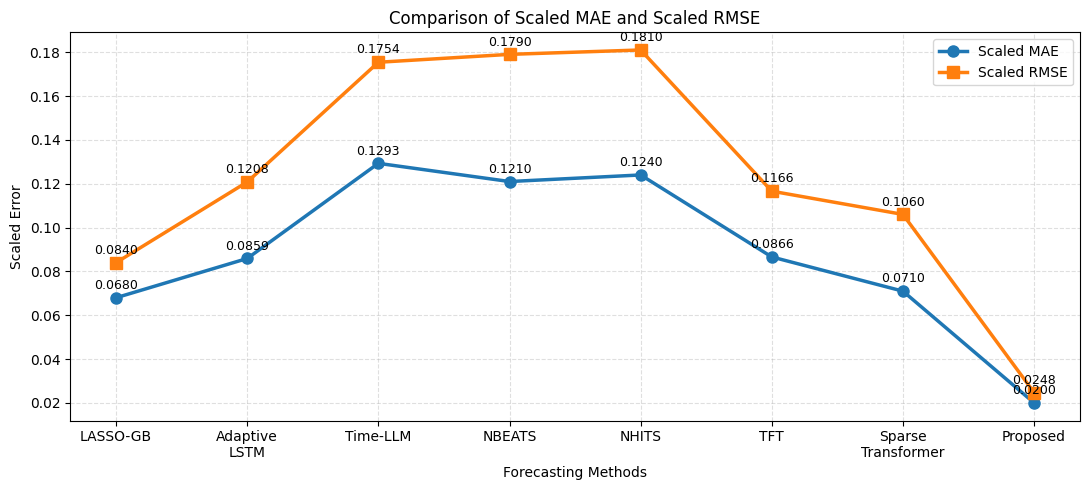

In [ ]:
import matplotlib.pyplot as plt

models = [
    "LASSO-GB",
    "Adaptive\nLSTM",
    "Time-LLM",
    "NBEATS",
    "NHITS",
    "TFT",
    "Sparse\nTransformer",
    "Proposed"
]

scaled_mae = [0.0680,0.0859,0.1293,0.1210,0.1240,0.0866,0.0710,0.02005]
scaled_rmse = [0.0840,0.1208,0.1754,0.1790,0.1810,0.1166,0.1060,0.02475]

plt.figure(figsize=(11,5))

plt.plot(models, scaled_mae,
         marker='o',
         linewidth=2.5,
         markersize=8,
         label='Scaled MAE')

plt.plot(models, scaled_rmse,
         marker='s',
         linewidth=2.5,
         markersize=8,
         label='Scaled RMSE')

# Value labels
for i, v in enumerate(scaled_mae):
    plt.text(i, v+0.004, f'{v:.4f}',
             ha='center',
             fontsize=9)

for i, v in enumerate(scaled_rmse):
    plt.text(i, v+0.004, f'{v:.4f}',
             ha='center',
             fontsize=9)

plt.xlabel("Forecasting Methods")
plt.ylabel("Scaled Error")
plt.title("Comparison of Scaled MAE and Scaled RMSE")
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend()

plt.tight_layout()
plt.show()

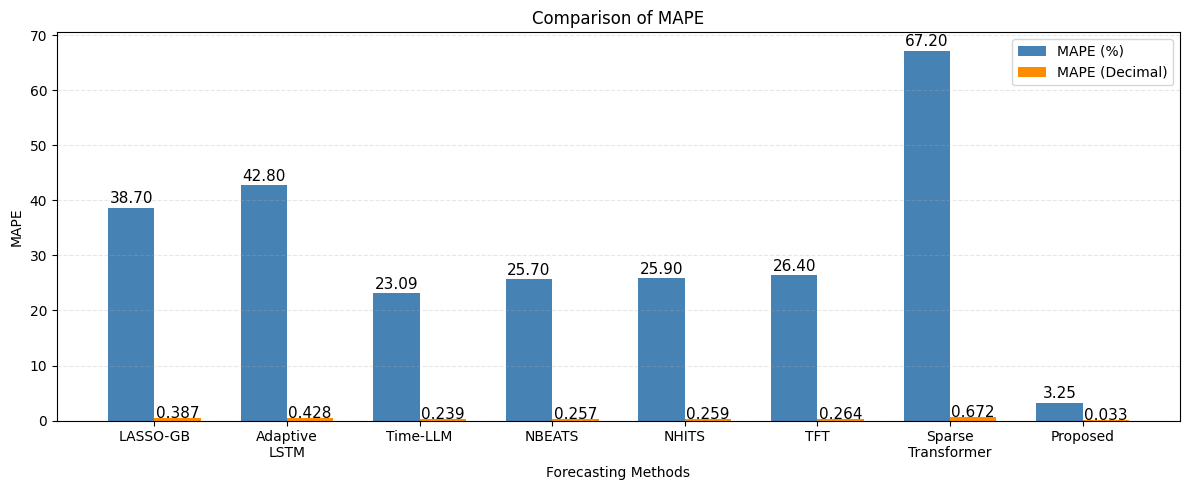

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = [
    "LASSO-GB",
    "Adaptive\nLSTM",
    "Time-LLM",
    "NBEATS",
    "NHITS",
    "TFT",
    "Sparse\nTransformer",
    "Proposed"
]

mape_percent = [38.7,42.8,23.09,25.7,25.9,26.4,67.2,3.25]
mape_decimal = [0.387,0.428,0.239,0.257,0.259,0.264,0.672,0.0325]

x = np.arange(len(models))
w = 0.35

fig, ax = plt.subplots(figsize=(12,5))

bars1 = ax.bar(x-w/2, mape_percent, w,
               label='MAPE (%)',
               color='steelblue')

bars2 = ax.bar(x+w/2, mape_decimal, w,
               label='MAPE (Decimal)',
               color='darkorange')

# ---------- Add values ----------
for bar in bars1:
    ax.text(bar.get_x()+bar.get_width()/2,
            bar.get_height()+0.8,
            f'{bar.get_height():.2f}',
            ha='center',
            fontsize=11)

for bar in bars2:
    ax.text(bar.get_x()+bar.get_width()/2,
            bar.get_height()+0.01,
            f'{bar.get_height():.3f}',
            ha='center',
            fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels(models)

ax.set_ylabel("MAPE")
ax.set_xlabel("Forecasting Methods")
ax.set_title("Comparison of MAPE")
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

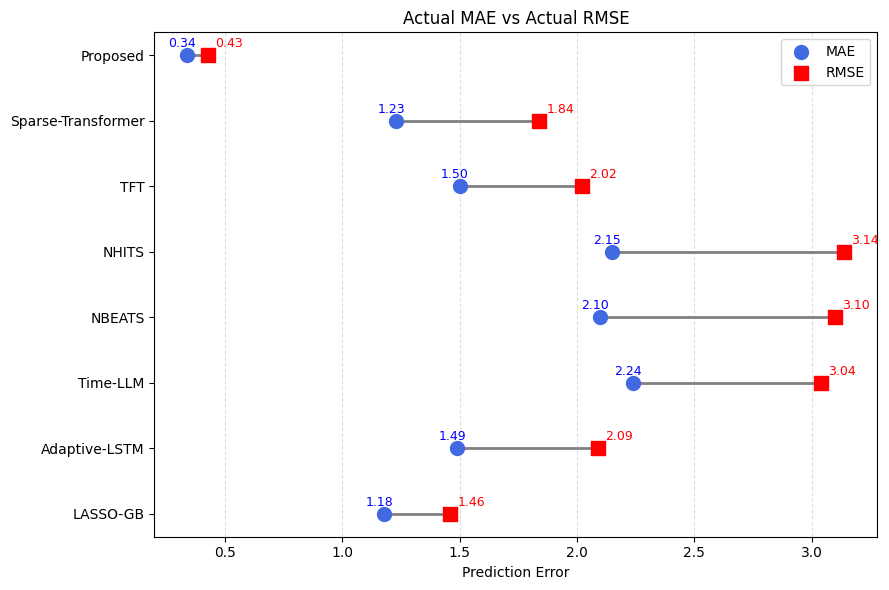

In [ ]:
import matplotlib.pyplot as plt

models = [
    'LASSO-GB',
    'Adaptive-LSTM',
    'Time-LLM',
    'NBEATS',
    'NHITS',
    'TFT',
    'Sparse-Transformer',
    'Proposed'
]

mae = [1.18,1.49,2.24,2.10,2.15,1.50,1.23,0.34]
rmse=[1.46,2.09,3.04,3.10,3.14,2.02,1.84,0.43]

plt.figure(figsize=(9,6))

for i in range(len(models)):
    plt.plot([mae[i],rmse[i]],[i,i],
             color='gray',
             linewidth=2)

plt.scatter(mae,
            range(len(models)),
            color='royalblue',
            s=100,
            label='MAE',
            zorder=3)

plt.scatter(rmse,
            range(len(models)),
            color='red',
            s=100,
            marker='s',
            label='RMSE',
            zorder=3)

# Value labels
for i,v in enumerate(mae):
    plt.text(v-0.08,i+0.12,f'{v:.2f}',fontsize=9,color='blue')

for i,v in enumerate(rmse):
    plt.text(v+0.03,i+0.12,f'{v:.2f}',fontsize=9,color='red')

plt.yticks(range(len(models)),models)

plt.xlabel("Prediction Error")
plt.title("Actual MAE vs Actual RMSE")

plt.grid(axis='x',linestyle='--',alpha=.4)

plt.legend()

plt.tight_layout()
plt.show()

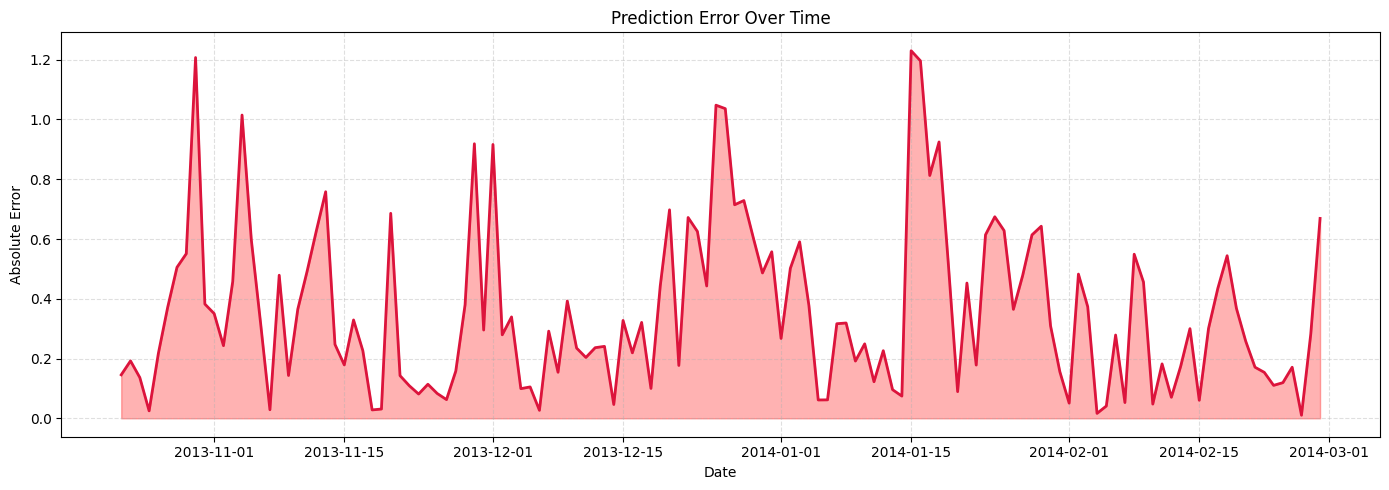

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Actual values
actual = y_test_lgb.values

# Predicted values
pred = final_pred

# Absolute error
error = np.abs(actual - pred)

plt.figure(figsize=(14,5))

plt.plot(test_df['day'], error,
         color='crimson',
         linewidth=2)

plt.fill_between(test_df['day'],
                 error,
                 alpha=0.3,
                 color='red')

plt.xlabel("Date")
plt.ylabel("Absolute Error")
plt.title("Prediction Error Over Time")

plt.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

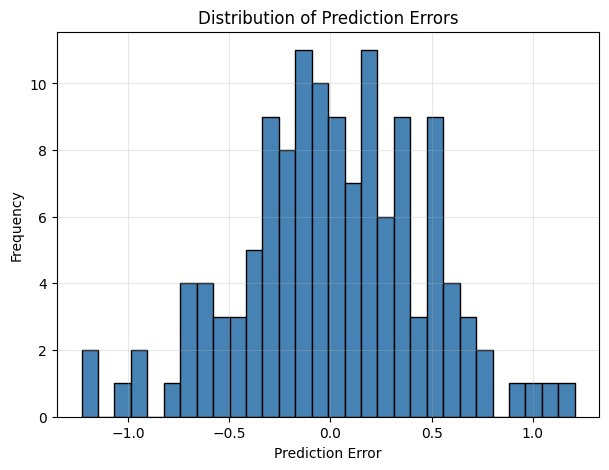

In [ ]:
import matplotlib.pyplot as plt

errors = actual - pred

plt.figure(figsize=(7,5))

plt.hist(errors,
         bins=30,
         color='steelblue',
         edgecolor='black')

plt.xlabel("Prediction Error")

plt.ylabel("Frequency")

plt.title("Distribution of Prediction Errors")

plt.grid(alpha=.3)

plt.show()

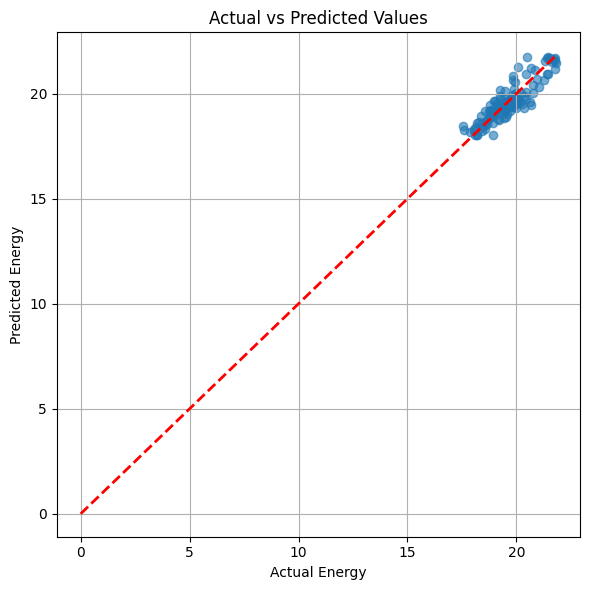

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(6,6))

plt.scatter(actual,
            pred,
            alpha=0.6)

# Ideal line
m = max(actual.max(), pred.max())
plt.plot([0,m],[0,m],'r--',linewidth=2)

plt.xlabel("Actual Energy")

plt.ylabel("Predicted Energy")

plt.title("Actual vs Predicted Values")

plt.grid(True)

plt.tight_layout()

plt.show()

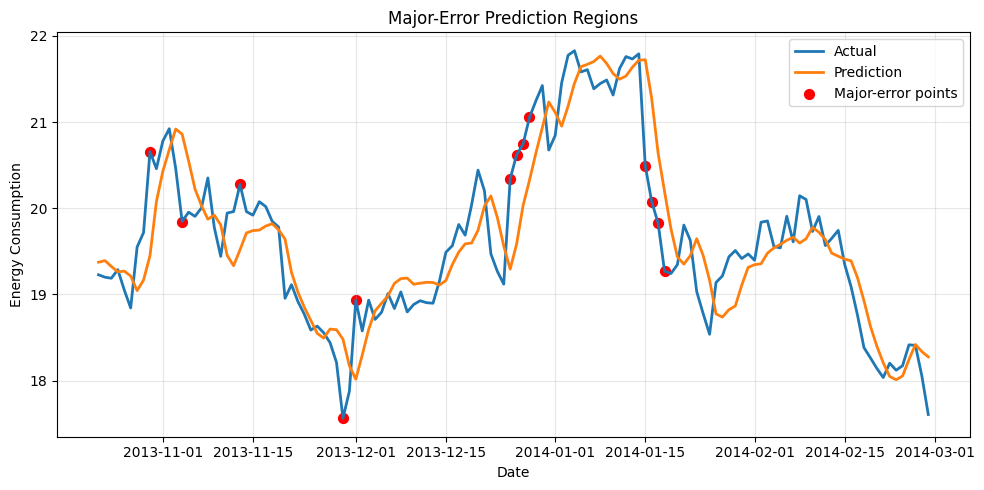

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

actual = y_test_lgb.values
pred = final_pred
error = np.abs(actual-pred)

threshold = np.percentile(error,90)

plt.figure(figsize=(10,5))

plt.plot(test_df['day'],actual,
         label='Actual',
         linewidth=2)

plt.plot(test_df['day'],pred,
         label='Prediction',
         linewidth=2)

high = error > threshold

plt.scatter(test_df['day'][high],
            actual[high],
            color='red',
            s=50,
            label='Major-error points')

plt.xlabel("Date")

plt.ylabel("Energy Consumption")

plt.title("Major-Error Prediction Regions")

plt.legend()

plt.grid(alpha=.3)

plt.tight_layout()

plt.show()